# AI Model Experiment & Evaluation

**Individual Assignment — AI Engineering Bootcamp**

Notebook ini membandingkan dua pendekatan untuk **sentiment analysis** ulasan pelanggan e-commerce:

1. **Model klasik:** TF-IDF + Logistic Regression (Scikit-learn)
2. **LLM API:** Gemini API dengan zero-shot prompting

> **Catatan penting:** Dataset memiliki 200 baris tetapi hanya 40 review unik. Karena banyak review berulang, random row split dapat menyebabkan **data leakage**. Notebook ini menggunakan **group-aware holdout berdasarkan review_text unik**, sehingga review yang sama tidak muncul di train dan test.



## 1. Problem Statement

### Objective
Membangun dan membandingkan dua pendekatan AI untuk mengklasifikasikan ulasan pelanggan e-commerce menjadi **positif** atau **negatif**.

### Target / Label
- positif
- negatif

### Dataset
Dataset customer_reviews_sentiment.csv berisi data ulasan pelanggan dengan kolom:
review_id, product_name, review_text, dan sentiment.

### Batasan dan asumsi
- Hanya dua kelas sentimen yang digunakan.
- Kedua pendekatan dievaluasi pada **test set yang sama**.
- Karena terdapat banyak duplicate review_text, split dilakukan berdasarkan review unik untuk mengurangi data leakage.
- Gemini membutuhkan API key yang disimpan di **Google Colab Secrets** dengan nama GEMINI_API_KEY.
- Hasil eksperimen Gemini harus berasal dari pemanggilan API nyata; metrik tidak boleh diisi secara manual.
- Menggunakan Google Collab karena terkendala device


## 2. Install Library, Import & Load Dataset

Notebook ini dibuat agar dapat langsung dijalankan di **Google Colab**.


In [1]:
# Install package yang dibutuhkan di Google Colab
!pip -q install -U google-genai scikit-learn python-dotenv


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 29.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.9/267.9 kB 8.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


In [2]:
from google.colab import files
from pathlib import Path
import os
import json
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Upload dataset
uploaded = files.upload()

# Ambil file CSV yang di-upload
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if not csv_files:
    raise FileNotFoundError("Tidak ada file CSV yang di-upload.")

DATA_PATH = csv_files[0]
df = pd.read_csv(DATA_PATH)

print("Dataset path:", DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

print("\nKolom:", df.columns.tolist())
print("\nLabel distribution:")
display(df["sentiment"].value_counts())

# Validasi struktur dataset
required_columns = {"review_id", "product_name", "review_text", "sentiment"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_columns}")

expected_labels = {"positif", "negatif"}
actual_labels = set(df["sentiment"].dropna().unique())
if not actual_labels.issubset(expected_labels):
    raise ValueError(f"Ditemukan label di luar {expected_labels}: {actual_labels - expected_labels}")


Saving customer_reviews_sentiment.csv to customer_reviews_sentiment.csv
Dataset path: customer_reviews_sentiment.csv
Dataset shape: (200, 4)


,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif



Kolom: ['review_id', 'product_name', 'review_text', 'sentiment']

Label distribution:


,count
sentiment,
positif,110
negatif,90


## 3. Menyiapkan Train/Test Split

Assignment mewajibkan kedua pendekatan diuji pada **test set yang sama**.

Pemeriksaan awal menunjukkan bahwa 200 baris hanya memiliki 40 review unik. Jika dilakukan random row split, review yang sama dapat masuk ke train dan test sehingga hasil evaluasi menjadi terlalu optimistis.

Karena itu, split dilakukan terhadap **review unik**, kemudian seluruh baris dengan review yang sama ditempatkan dalam kelompok yang sama. Dengan cara ini tidak ada exact duplicate review yang bocor dari train ke test.

> Ini adalah penyesuaian metodologis untuk membuat evaluasi lebih valid; dataset asli tidak diubah.

In [3]:
# Validasi duplicate
print("Jumlah baris:", len(df))
print("Jumlah review unik:", df["review_text"].nunique())
print("Baris yang merupakan duplicate:", df["review_text"].duplicated(keep=False).sum())

# Buat tabel unik untuk menentukan group split
unique_reviews = df[["review_text", "sentiment"]].drop_duplicates()

train_unique, test_unique = train_test_split(
    unique_reviews,
    test_size=0.20,
    random_state=42,
    stratify=unique_reviews["sentiment"]
)

test_review_keys = set(test_unique["review_text"])

train_df = df[~df["review_text"].isin(test_review_keys)].copy()
test_df = df[df["review_text"].isin(test_review_keys)].copy()

X_train = train_df["review_text"]
y_train = train_df["sentiment"]
X_test = test_df["review_text"]
y_test = test_df["sentiment"]

print("Train rows:", len(train_df))
print("Test rows:", len(test_df))
print("Train unique reviews:", train_df["review_text"].nunique())
print("Test unique reviews:", test_df["review_text"].nunique())
print("\nTest label distribution:")
display(y_test.value_counts())

# Pastikan tidak ada duplicate review yang overlap
assert set(train_df["review_text"]).isdisjoint(set(test_df["review_text"]))
print("\n✓ Tidak ada review_text yang overlap antara train dan test.")


Jumlah baris: 200
Jumlah review unik: 40
Baris yang merupakan duplicate: 198
Train rows: 158
Test rows: 42
Train unique reviews: 32
Test unique reviews: 8

Test label distribution:


,count
sentiment,
negatif,24
positif,18



✓ Tidak ada review_text yang overlap antara train dan test.


## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

TF-IDF mengubah teks menjadi representasi numerik berdasarkan bobot kata/term. Digunakan unigram + bigram agar model dapat menangkap frasa sederhana seperti tidak bagus.

In [4]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2)
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Train matrix:", X_train_vec.shape)
print("Test matrix:", X_test_vec.shape)

Train matrix: (158, 329)
Test matrix: (42, 329)


### 4.2 Training Model

In [5]:
clf = LogisticRegression(
    max_iter=1000,
    random_state=42
)

clf.fit(X_train_vec, y_train)
print("Training selesai.")

Training selesai.


### 4.3 Prediksi pada Test Set

In [6]:
y_pred_classic = clf.predict(X_test_vec)

classic_results = test_df[["review_id", "product_name", "review_text", "sentiment"]].copy()
classic_results["predicted_sentiment"] = y_pred_classic
display(classic_results.head(10))

,review_id,product_name,review_text,sentiment,predicted_sentiment
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif,positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif,positif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif,positif
15,16,Sepatu Sneakers,"Pengiriman lambat sekali, sudah dua minggu bel...",negatif,negatif
16,17,Headset Bluetooth,"Pengiriman lambat sekali, sudah dua minggu bel...",negatif,negatif
17,18,Jaket Hoodie,"Puas banget belanja disini, proses cepat dan b...",positif,positif
23,24,Kaos Polos,Respon penjual lambat dan terkesan tidak pedul...,negatif,positif
25,26,Botol Minum,"Pengiriman lambat sekali, sudah dua minggu bel...",negatif,negatif
30,31,Case HP,"Ukuran dan warna berbeda dari pesanan, sangat ...",negatif,positif
35,36,Rice Cooker,Respon penjual lambat dan terkesan tidak pedul...,negatif,positif


### 5.1 Setup Gemini API

API key tidak ditulis langsung di notebook.

Di Google Colab:
1. Buka panel **Secrets** (ikon kunci).
2. Tambahkan secret dengan nama GEMINI_API_KEY.
3. Isi dengan API key Gemini Anda.
4. Aktifkan akses notebook ke secret tersebut.

In [23]:
from google.colab import userdata
try:
    # Mengambil secret dengan nama yang benar: 'GEMINI_API_KEY'
    api_key = userdata.get('GEMINI_API_KEY')
    print("✓ Berhasil mendapatkan GEMINI_API_KEY.")
except Exception as e:
    print("Gagal mendapatkan GEMINI_API_KEY. Pastikan sudah didaftarkan di menu Secrets (ikon kunci).", e)

✓ Berhasil mendapatkan GEMINI_API_KEY.


In [7]:
from google.colab import userdata
from google import genai
from google.genai import types

# Ambil API key dari Google Colab Secrets
try:
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    GEMINI_API_KEY = None

if not GEMINI_API_KEY:
    client = None
    print("GEMINI_API_KEY belum tersedia.")
    print("Tambahkan GEMINI_API_KEY di Google Colab Secrets, lalu jalankan kembali cell ini.")
else:
    client = genai.Client(api_key=GEMINI_API_KEY)
    print("✓ Gemini client siap.")


✓ Gemini client siap.


In [8]:
# Cek status Gemini client
print("Gemini client tersedia:", client is not None)


Gemini client tersedia: True


### 5.2 Merancang Prompt

Pendekatan yang digunakan adalah **zero-shot classification**. Kita menggunakan zero-shot karena pendekatan ini memanfaatkan kemampuan dasar LLM yang sudah sangat baik (Out-of-the-box Capability), menghemat latency dan biaya (Cost & Token Efficiency), serta menyederhanakan kompleksitas tugas. Oleh karena itu, pendekatan zero-shot lebih sesuai.

**Model:** gemini-3.5-flash-lite

**Temperature:** 0.0, agar output klasifikasi lebih konsisten.

**Max output tokens:** 5, karena output yang diharapkan hanya satu kata.

In [16]:
GEMINI_MODEL = "gemini-3.5-flash-lite"
TEMPERATURE = 0.0
MAX_OUTPUT_TOKENS = 5

def build_prompt(review_text: str) -> str:
    return f'''Anda adalah classifier sentimen untuk review pelanggan e-commerce.

Tentukan sentimen review berikut menjadi tepat salah satu:
- positif
- negatif

Aturan:
1. Jawab HANYA dengan satu kata: positif atau negatif.
2. Jangan berikan penjelasan.
3. Gunakan makna keseluruhan review.

Review:
{review_text}

Jawaban:'''

def normalize_llm_output(text: str) -> str:
    text = (text or "").strip().lower()
    # Toleransi terhadap pemotongan kata atau singkatan dari LLM
    if "posit" in text or "pos" in text:
        return "positif"
    if "negat" in text or "neg" in text:
        return "negatif"
    return "invalid"

### 5.3 Menjalankan Prediksi pada Test Set

Untuk menghemat API call, notebook melakukan **caching berdasarkan review_text unik**. Karena duplicate review memiliki input yang identik, satu hasil Gemini dapat dipetakan kembali ke semua baris test dengan review yang sama. Ini tidak mengubah test set atau label evaluasi.

In [17]:
def classify_sentiment_llm(review_text: str) -> str:
    if client is None:
        raise RuntimeError("GEMINI_API_KEY belum diset.")

    response = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=build_prompt(review_text),
        config=types.GenerateContentConfig(
            temperature=TEMPERATURE,
            max_output_tokens=MAX_OUTPUT_TOKENS
        )
    )

    raw_output = response.text or ""
    normalized = normalize_llm_output(raw_output)

    print(
        f"Review: {review_text[:50]}... "
        f"-> Raw: '{raw_output.strip()}' "
        f"-> Normalized: {normalized}"
    )
    return normalized


if client is None:
    y_pred_llm = None
    print("Gemini belum dijalankan karena API key belum tersedia.")
else:
    llm_cache = {}
    unique_test_reviews = test_df["review_text"].drop_duplicates().tolist()

    print(f"Jumlah unique review pada test set: {len(unique_test_reviews)}")
    print("Memulai prediksi menggunakan Gemini...")

    for i, review in enumerate(unique_test_reviews, start=1):
        last_output = None

        for attempt in range(3):
            try:
                prediction = classify_sentiment_llm(review)
                last_output = prediction

                if prediction in {"positif", "negatif"}:
                    llm_cache[review] = prediction
                    break

                print(f"Output invalid untuk review {i}; retry {attempt + 1}/3.")
                time.sleep(1)

            except Exception as e:
                print(f"Error review {i}, attempt {attempt + 1}/3: {e}")
                time.sleep(2)

        if review not in llm_cache:
            raise RuntimeError(
                f"Gemini gagal menghasilkan label valid setelah 3 percobaan "
                f"untuk review ke-{i}. Output terakhir: {last_output}"
            )

    y_pred_llm = test_df["review_text"].map(llm_cache).tolist()

    # Pastikan semua prediksi valid
    assert set(y_pred_llm).issubset({"positif", "negatif"})

    llm_results = test_df[
        ["review_id", "product_name", "review_text", "sentiment"]
    ].copy()
    llm_results["predicted_sentiment"] = y_pred_llm

    print("\n✓ Semua prediksi Gemini valid.")
    display(llm_results.head(10))



Jumlah unique review pada test set: 8
Memulai prediksi menggunakan Gemini...
Review: Puas banget belanja disini, proses cepat dan baran... -> Raw: 'posit' -> Normalized: positif
Review: Terima kasih seller, barangnya awet dan sesuai des... -> Raw: 'posit' -> Normalized: positif
Review: Pengiriman lambat sekali, sudah dua minggu belum s... -> Raw: 'neg' -> Normalized: negatif
Review: Respon penjual lambat dan terkesan tidak peduli ko... -> Raw: 'neg' -> Normalized: negatif
Review: Ukuran dan warna berbeda dari pesanan, sangat kece... -> Raw: 'neg' -> Normalized: negatif
Review: Pelayanan ramah dan responsif, barang sampai lebih... -> Raw: 'posit' -> Normalized: positif
Review: Komplain tidak ditanggapi sama sekali oleh penjual... -> Raw: 'neg' -> Normalized: negatif
Review: Harga worth it dengan kualitas yang didapat, sanga... -> Raw: 'posit' -> Normalized: positif

✓ Semua prediksi Gemini valid.


,review_id,product_name,review_text,sentiment,predicted_sentiment
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif,positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif,positif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif,positif
15,16,Sepatu Sneakers,"Pengiriman lambat sekali, sudah dua minggu bel...",negatif,negatif
16,17,Headset Bluetooth,"Pengiriman lambat sekali, sudah dua minggu bel...",negatif,negatif
17,18,Jaket Hoodie,"Puas banget belanja disini, proses cepat dan b...",positif,positif
23,24,Kaos Polos,Respon penjual lambat dan terkesan tidak pedul...,negatif,negatif
25,26,Botol Minum,"Pengiriman lambat sekali, sudah dua minggu bel...",negatif,negatif
30,31,Case HP,"Ukuran dan warna berbeda dari pesanan, sangat ...",negatif,negatif
35,36,Rice Cooker,Respon penjual lambat dan terkesan tidak pedul...,negatif,negatif


## 6. Evaluasi dan Perbandingan

Metrik yang digunakan:
- **Accuracy:** proporsi seluruh prediksi yang benar.
- **Precision:** dari semua prediksi positif, proporsi yang benar-benar positif.
- **Recall:** dari seluruh review yang sebenarnya positif, proporsi yang berhasil ditemukan.
- **F1-score:** harmonic mean antara precision dan recall.
- **Confusion matrix:** menunjukkan jumlah prediksi benar/salah untuk masing-masing kelas.

In [18]:
def evaluate_model(y_true, y_pred, model_name):
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label="positif", zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label="positif", zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, pos_label="positif", zero_division=0)
    }

    print(f"=== {model_name} ===")
    print(classification_report(
        y_true, y_pred,
        labels=["negatif", "positif"],
        zero_division=0
    ))
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred, labels=["negatif", "positif"]))

    return metrics

classic_metrics = evaluate_model(y_test, y_pred_classic, "TF-IDF + Logistic Regression")

=== TF-IDF + Logistic Regression ===
              precision    recall  f1-score   support

     negatif       1.00      0.46      0.63        24
     positif       0.58      1.00      0.73        18

    accuracy                           0.69        42
   macro avg       0.79      0.73      0.68        42
weighted avg       0.82      0.69      0.67        42

Confusion Matrix:
[[11 13]
 [ 0 18]]


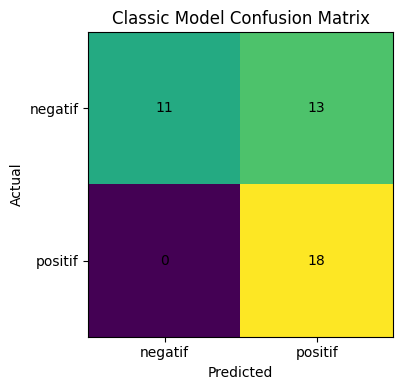

In [19]:
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=["negatif", "positif"])

    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm)
    ax.set_xticks([0, 1], ["negatif", "positif"])
    ax.set_yticks([0, 1], ["negatif", "positif"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)

    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

    plt.tight_layout()
    plt.show()

plot_confusion_matrix(y_test, y_pred_classic, "Classic Model Confusion Matrix")

### 6.2 Evaluasi LLM API

=== Gemini API ===
              precision    recall  f1-score   support

     negatif       1.00      1.00      1.00        24
     positif       1.00      1.00      1.00        18

    accuracy                           1.00        42
   macro avg       1.00      1.00      1.00        42
weighted avg       1.00      1.00      1.00        42

Confusion Matrix:
[[24  0]
 [ 0 18]]


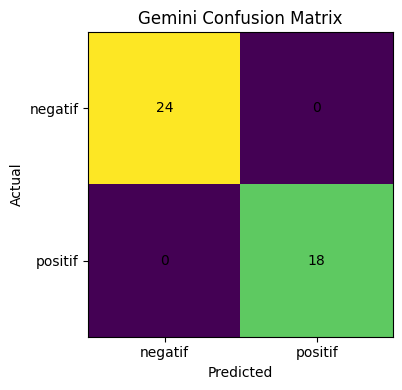

In [20]:
if y_pred_llm is not None:
    llm_metrics = evaluate_model(y_test, y_pred_llm, "Gemini API")
    plot_confusion_matrix(y_test, y_pred_llm, "Gemini Confusion Matrix")
else:
    llm_metrics = None
    print("Belum ada hasil Gemini. Tambahkan GEMINI_API_KEY di Colab Secrets lalu jalankan ulang cell Gemini.")


### 6.3 Tabel Perbandingan Ringkasan

Meminta kedua pendekatan dibandingkan menggunakan **test set yang sama**.

In [21]:
comparison = pd.DataFrame([classic_metrics])

if llm_metrics is not None:
    comparison = pd.concat(
        [comparison, pd.DataFrame([llm_metrics])],
        ignore_index=True
    )

display(comparison)

# Simpan hasil eksperimen
results_dir = Path("/content/results")
results_dir.mkdir(exist_ok=True)

comparison.to_csv(results_dir / "comparison_metrics.csv", index=False)
comparison.to_json(
    results_dir / "comparison_metrics.json",
    orient="records",
    indent=2
)

classic_results.to_csv(
    results_dir / "classic_predictions.csv",
    index=False
)

if y_pred_llm is not None:
    llm_results.to_csv(
        results_dir / "llm_predictions.csv",
        index=False
    )

print("\nHasil disimpan di:", results_dir)


,Model,Accuracy,Precision,Recall,F1-Score
0,TF-IDF + Logistic Regression,0.690476,0.580645,1.0,0.734694
1,Gemini API,1.000000,1.000000,1.0,1.000000



Hasil disimpan di: /content/results


## 7. Analisis Trade-off dan Limitation

### Temuan dataset
Dataset mengandung banyak duplicate review_text: 200 baris tetapi hanya 40 review unik. Karena itu, random row split dapat menghasilkan performa yang terlalu optimistis. Group-aware split digunakan untuk mengurangi risiko leakage.

### Model klasik
**Kelebihan**
- Tidak membutuhkan API eksternal setelah model dilatih.
- Inference relatif cepat dan murah.
- Hasil lebih mudah direproduksi.

**Keterbatasan**
- Membutuhkan training dan preprocessing.
- Pemahaman konteks bahasa lebih terbatas dibanding LLM.
- Sangat bergantung pada kualitas dan representasi data training.

### Gemini API
**Kelebihan**
- Tidak perlu training model sendiri.
- Dapat langsung digunakan melalui prompt.
- Lebih fleksibel terhadap variasi bahasa dan konteks.

**Keterbatasan**
- Membutuhkan koneksi dan API key.
- Ada potensi biaya API dan latency.
- Output LLM perlu divalidasi.
- Hasil dapat berubah tergantung model, prompt, dan parameter.

In [28]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 8. Rekomendasi Technical Approach

Setelah Gemini dijalankan, gunakan tabel comparison untuk menentukan pendekatan.

Contoh pola keputusan:

- Jika Gemini memiliki performa lebih tinggi dan biaya/latency masih dapat diterima -> pertimbangkan Gemini.
- Jika model klasik memiliki performa setara/lebih tinggi dan volume inference tinggi -> model klasik dapat lebih ekonomis.
- Jika kebutuhan utama adalah kontrol biaya, latency, dan deployment lokal -> model klasik memiliki keunggulan.
- Jika fleksibilitas bahasa dan minimnya effort training lebih penting -> Gemini lebih menarik.

**Rekomendasi final harus mengikuti hasil eksperimen aktual**, bukan asumsi sebelum eksperimen.

## Appendix — Reproducibility

### Split
- Test size: 20% pada review unik
- Random state: 42
- Split dilakukan berdasarkan review_text unik untuk mengurangi exact-duplicate leakage.

### Classic model
- TfidfVectorizer(ngram_range=(1,2), lowercase=True)
- LogisticRegression(max_iter=1000, random_state=42)

### Gemini
- Model: gemini-3.5-flash
- Prompt: zero-shot
- Temperature: 0.0
- Max output tokens: 5
- Prediksi dilakukan pada test set yang sama dengan model klasik.

### API key
API key disimpan di Google Colab Secrets dengan nama GEMINI_API_KEY